# Loan Default Rate Prediction Model

This notebook implements a comprehensive machine learning pipeline to predict loan default probability.

## Project Overview
- **Goal**: Predict the probability of a borrower defaulting on a loan
- **Dataset**: Loan_default.csv with borrower and loan information
- **Models**: Logistic Regression, Random Forest, XGBoost
- **Evaluation**: Focus on imbalanced classification metrics

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning libraries
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Imbalanced learning
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# XGBoost
import xgboost as xgb

# Model persistence
import joblib

# Set random seed for reproducibility
np.random.seed(42)

# Set plotting style
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

## 1. Data Loading and Initial Exploration

In [2]:
# Load the dataset
df = pd.read_csv('Loan_default.csv')

print(f'Dataset shape: {df.shape}')
print(f'\nColumns: {list(df.columns)}')

# Display first few rows
df.head()

Dataset shape: (255347, 18)

Columns: ['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [3]:
# Basic information about the dataset
print('Data Types:')
print(df.dtypes)
print('\nMissing Values:')
print(df.isnull().sum())
print('\nBasic Statistics:')
df.describe()

Data Types:
LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object

Missing Values:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

Basic Statistics:


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


Target Variable Distribution:
Default
0    225694
1     29653
Name: count, dtype: int64

Default Rate: 0.1161


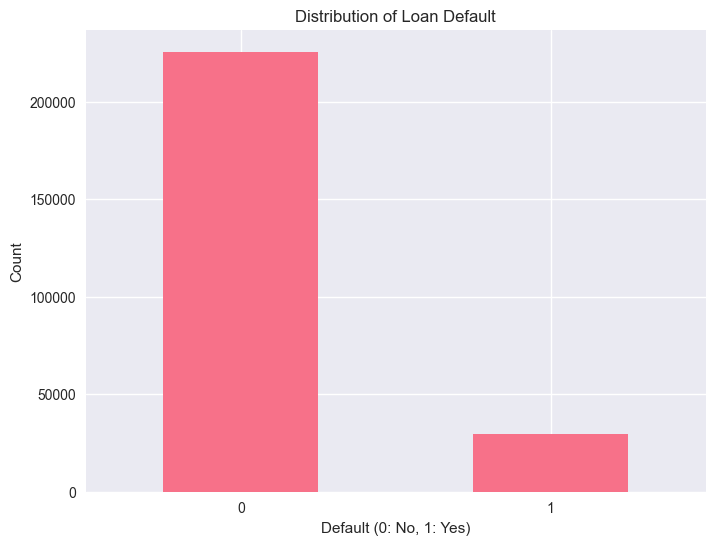

In [4]:
# Check target variable distribution
print('Target Variable Distribution:')
print(df['Default'].value_counts())
print(f'\nDefault Rate: {df["Default"].mean():.4f}')

# Visualize target distribution
plt.figure(figsize=(8, 6))
df['Default'].value_counts().plot(kind='bar')
plt.title('Distribution of Loan Default')
plt.xlabel('Default (0: No, 1: Yes)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

## 2. Exploratory Data Analysis (EDA)

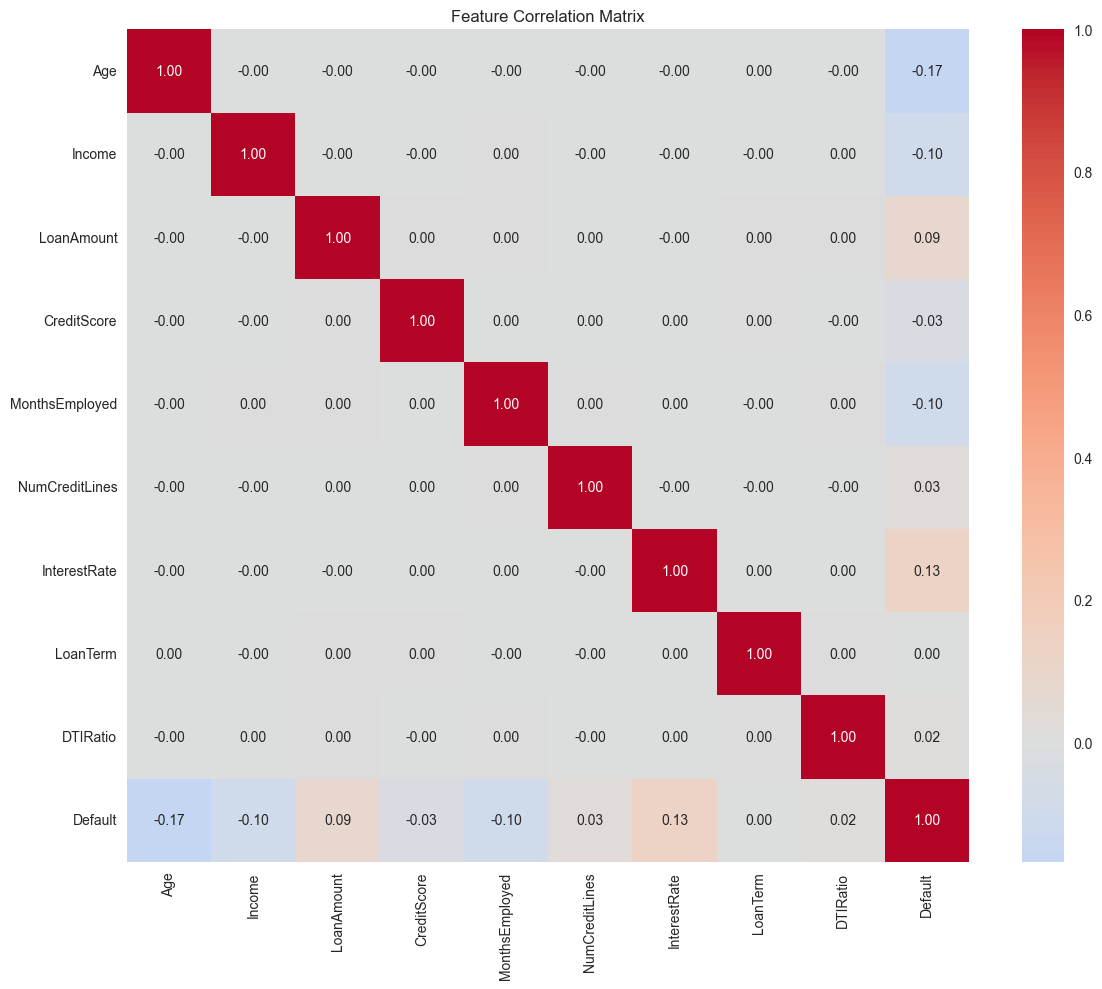

In [5]:
# Correlation matrix
plt.figure(figsize=(12, 10))
# Select only numeric columns for correlation
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()


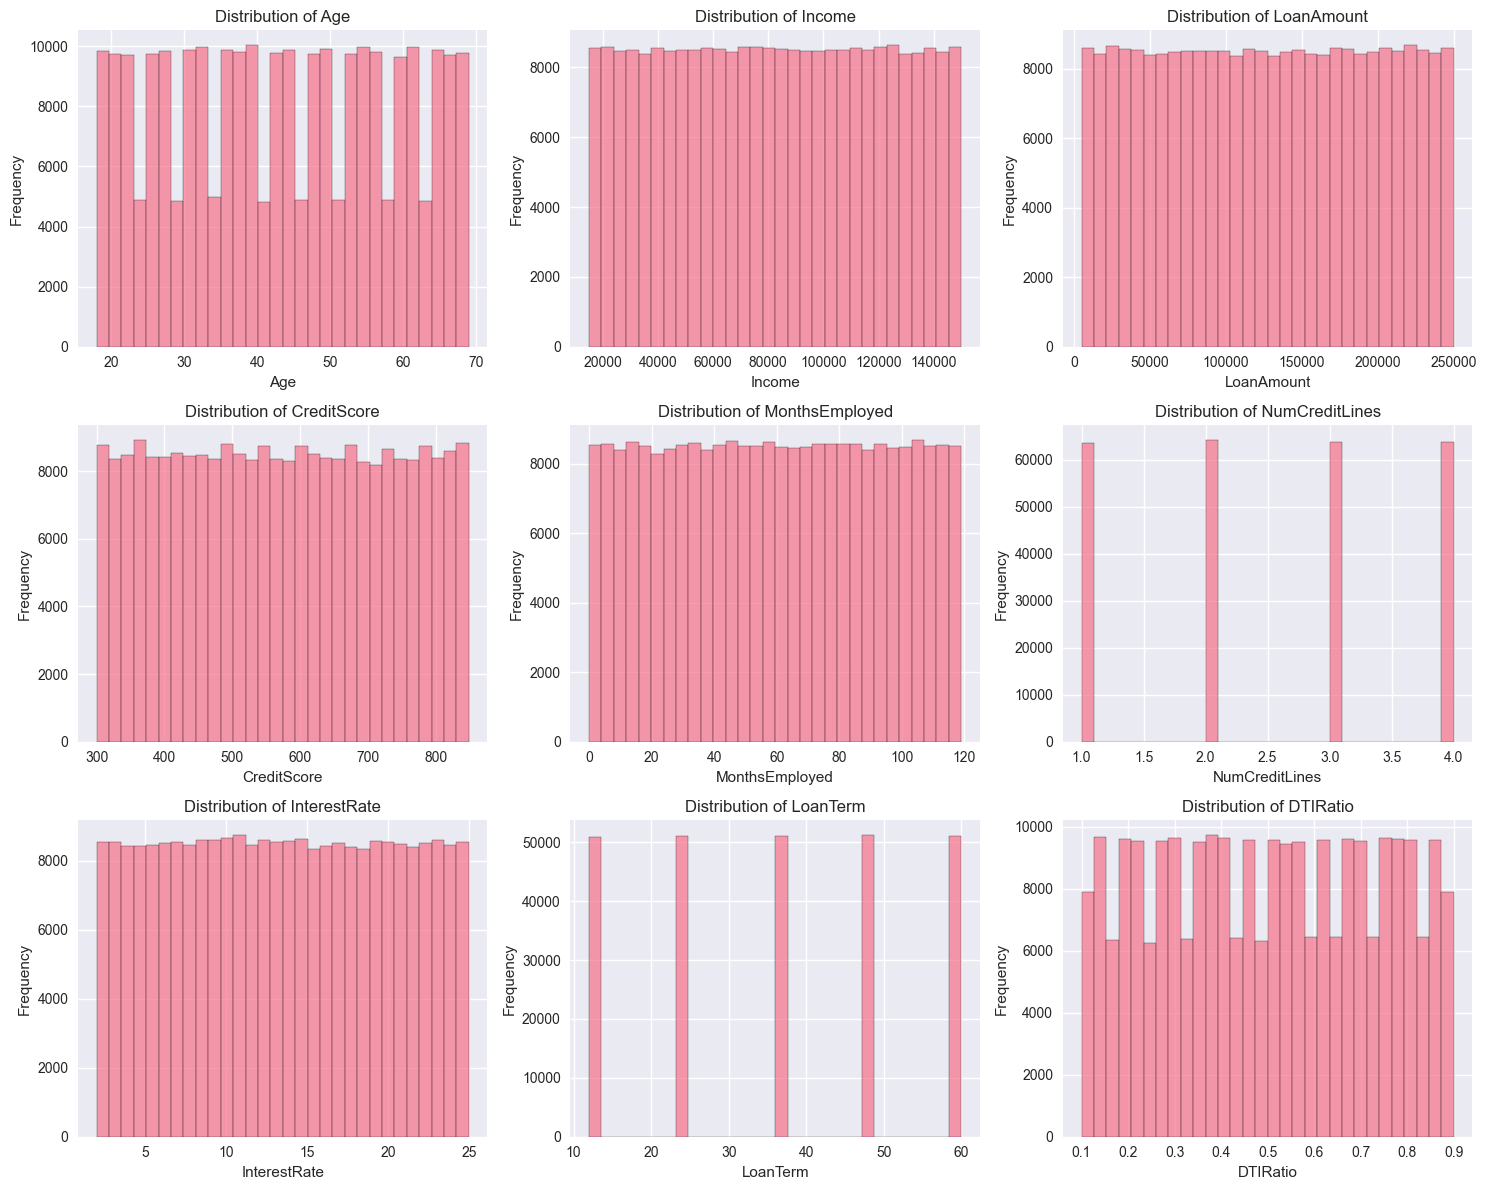

In [6]:
# Distribution of numerical features
numerical_cols = df.select_dtypes(include=[np.number]).columns.drop('Default')

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for i, col in enumerate(numerical_cols):
    if i < len(axes):
        axes[i].hist(df[col], bins=30, alpha=0.7, edgecolor='black')
        axes[i].set_title(f'Distribution of {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frequency')

# Hide unused subplots
for i in range(len(numerical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

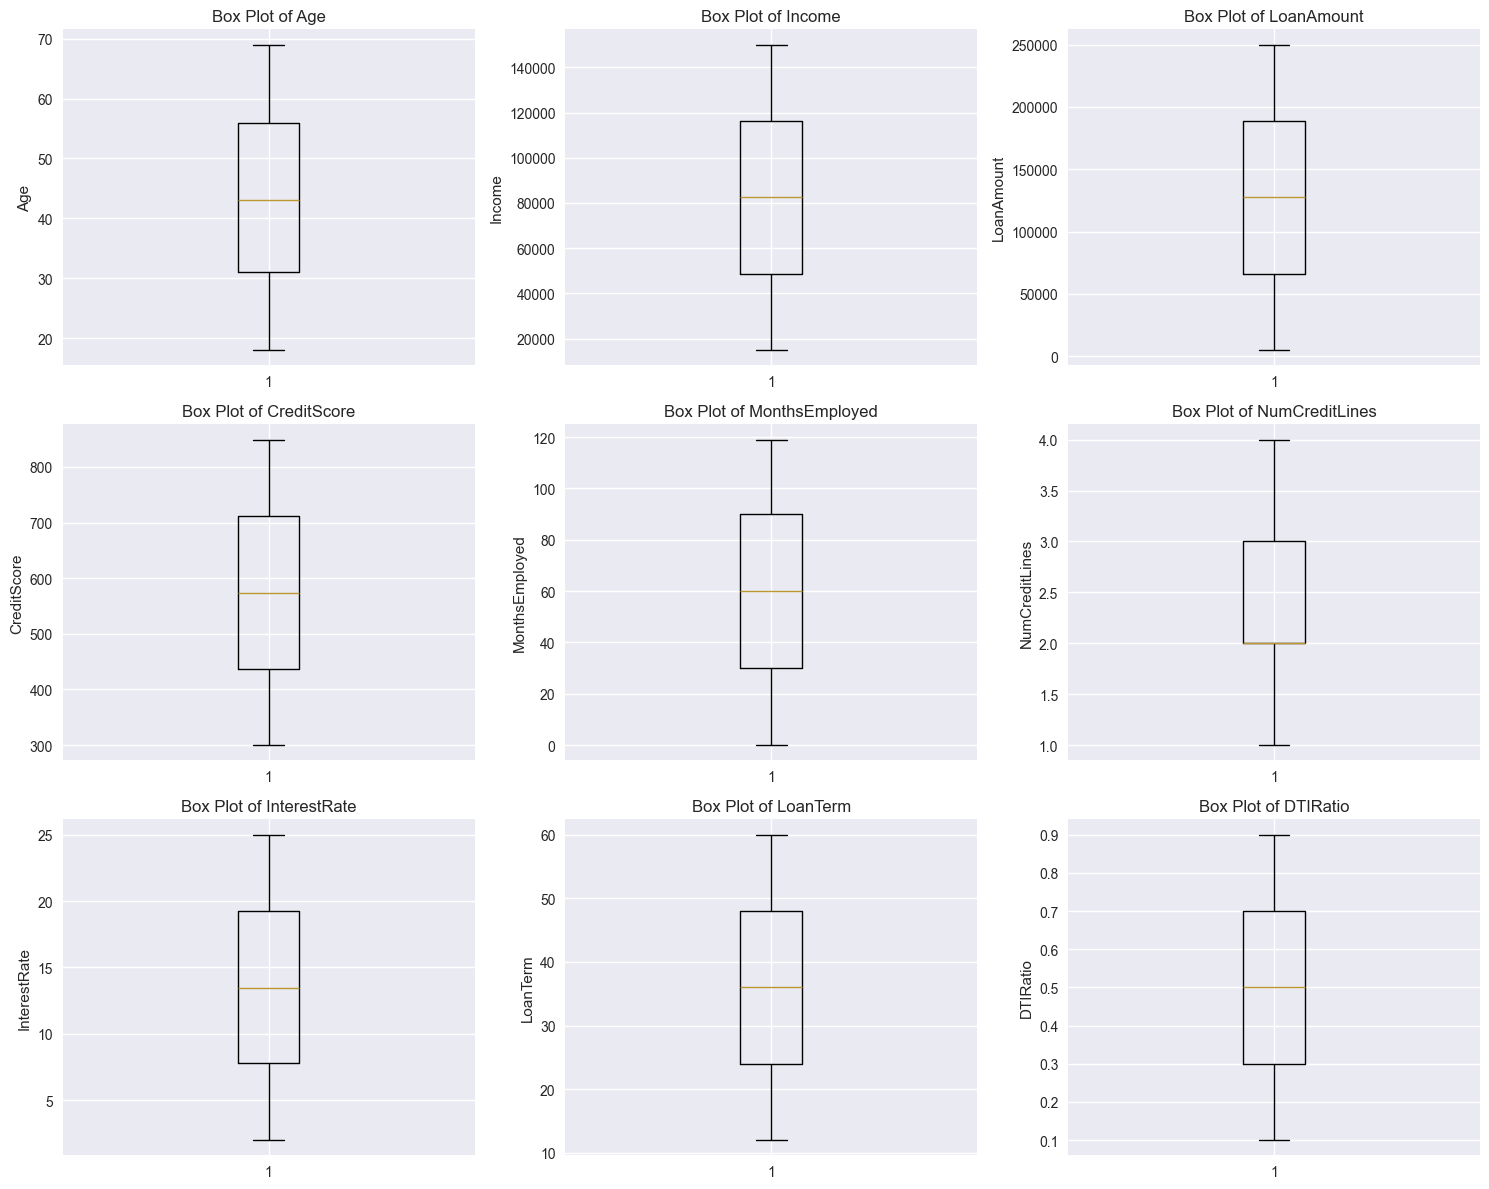

In [7]:
# Box plots to identify outliers
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for i, col in enumerate(numerical_cols):
    if i < len(axes):
        axes[i].boxplot(df[col])
        axes[i].set_title(f'Box Plot of {col}')
        axes[i].set_ylabel(col)

# Hide unused subplots
for i in range(len(numerical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

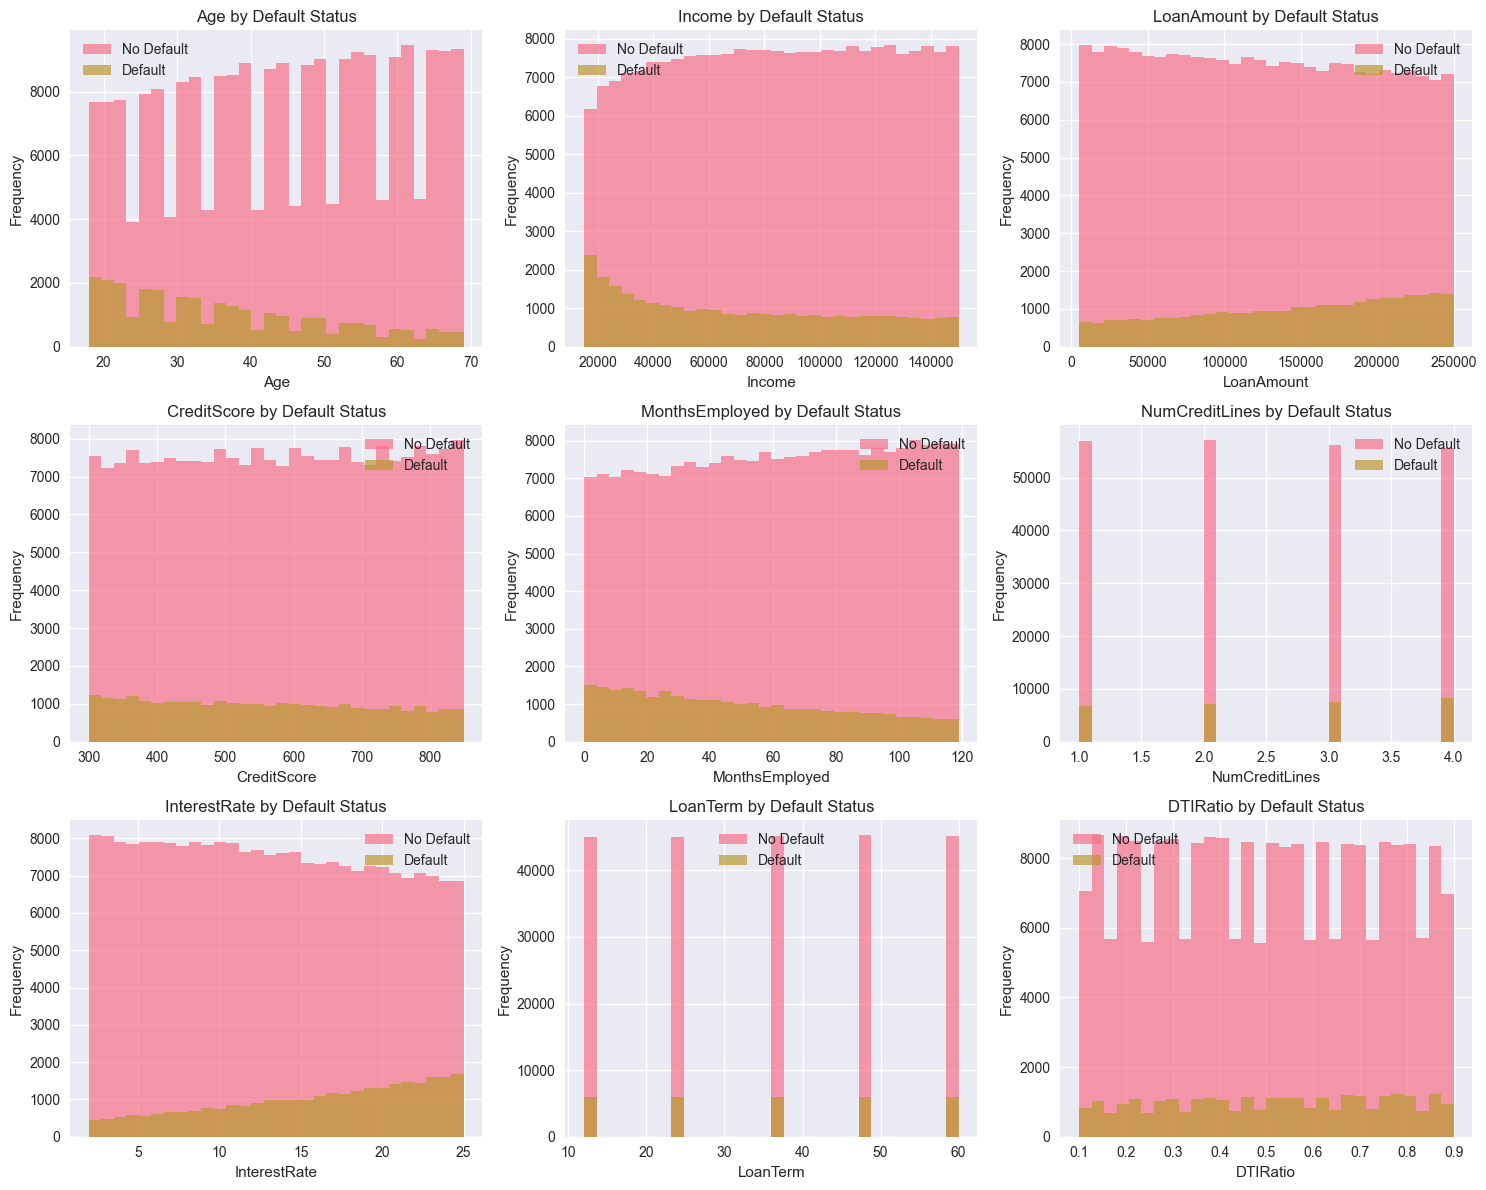

In [8]:
# Feature distributions by default status
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for i, col in enumerate(numerical_cols):
    if i < len(axes):
        df[df['Default'] == 0][col].hist(alpha=0.7, label='No Default', bins=30, ax=axes[i])
        df[df['Default'] == 1][col].hist(alpha=0.7, label='Default', bins=30, ax=axes[i])
        axes[i].set_title(f'{col} by Default Status')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frequency')
        axes[i].legend()

# Hide unused subplots
for i in range(len(numerical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

## 3. Data Preprocessing and Feature Engineering

In [9]:
# Create a copy for preprocessing
df_processed = df.copy()

# Handle missing values (if any)
print('Missing values before handling:')
print(df_processed.isnull().sum())

# Fill missing values with median for numerical columns
for col in df_processed.select_dtypes(include=[np.number]).columns:
    if df_processed[col].isnull().sum() > 0:
        df_processed[col].fillna(df_processed[col].median(), inplace=True)

print('\nMissing values after handling:')
print(df_processed.isnull().sum())

Missing values before handling:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

Missing values after handling:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64


In [10]:
# Feature Engineering
print('Creating new features...')

# Income to loan ratio
df_processed['income_to_loan_ratio'] = df_processed['Income'] / df_processed['LoanAmount']

# Age groups
df_processed['age_group'] = pd.cut(df_processed['Age'], 
                                   bins=[0, 30, 40, 50, 100], 
                                   labels=['Young', 'Middle_Young', 'Middle_Old', 'Senior'])

# Credit score categories
df_processed['credit_score_category'] = pd.cut(df_processed['CreditScore'], 
                                               bins=[0, 600, 700, 800, 900], 
                                               labels=['Poor', 'Fair', 'Good', 'Excellent'])

# DTI categories
df_processed['dti_category'] = pd.cut(df_processed['DTIRatio'], 
                                     bins=[0, 0.3, 0.5, 0.7, 1.0], 
                                     labels=['Low', 'Medium', 'High', 'Very_High'])

print('New features created successfully!')

Creating new features...
New features created successfully!


In [11]:
# Outlier detection and treatment using IQR method
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

# Apply outlier removal to key numerical features
print(f'Original dataset size: {len(df_processed)}')

outlier_columns = ['Income', 'LoanAmount', 'CreditScore', 'DTIRatio']
for col in outlier_columns:
    before_size = len(df_processed)
    df_processed = remove_outliers_iqr(df_processed, col)
    after_size = len(df_processed)
    print(f'Removed {before_size - after_size} outliers from {col}')

print(f'Final dataset size: {len(df_processed)}')

Original dataset size: 255347
Removed 0 outliers from Income
Removed 0 outliers from LoanAmount
Removed 0 outliers from CreditScore
Removed 0 outliers from DTIRatio
Final dataset size: 255347


In [12]:
# Encode categorical variables
categorical_columns = ['age_group', 'credit_score_category', 'dti_category']

# One-hot encoding for categorical variables
df_encoded = pd.get_dummies(df_processed, columns=categorical_columns, drop_first=True)

print(f'Dataset shape after encoding: {df_encoded.shape}')
print(f'New columns: {[col for col in df_encoded.columns if col not in df_processed.columns]}')

Dataset shape after encoding: (255347, 28)
New columns: ['age_group_Middle_Young', 'age_group_Middle_Old', 'age_group_Senior', 'credit_score_category_Fair', 'credit_score_category_Good', 'credit_score_category_Excellent', 'dti_category_Medium', 'dti_category_High', 'dti_category_Very_High']


## 4. Model Preparation and Training

In [13]:
# Prepare features and target
X = df_encoded.drop('Default', axis=1)
y = df_encoded['Default']

print(f'Features shape: {X.shape}')
print(f'Target shape: {y.shape}')
print(f'Feature columns: {list(X.columns)}')

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Training set size: {X_train.shape[0]}')
print(f'Test set size: {X_test.shape[0]}')
print(f'Training default rate: {y_train.mean():.4f}')
print(f'Test default rate: {y_test.mean():.4f}')

Features shape: (255347, 27)
Target shape: (255347,)
Feature columns: ['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'income_to_loan_ratio', 'age_group_Middle_Young', 'age_group_Middle_Old', 'age_group_Senior', 'credit_score_category_Fair', 'credit_score_category_Good', 'credit_score_category_Excellent', 'dti_category_Medium', 'dti_category_High', 'dti_category_Very_High']


Training set size: 204277
Test set size: 51070
Training default rate: 0.1161
Test default rate: 0.1161


In [14]:
# Feature scaling
# Drop non-numeric columns before scaling
X_train_numeric = X_train.select_dtypes(include=[np.number])
X_test_numeric = X_test.select_dtypes(include=[np.number])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_numeric)
X_test_scaled = scaler.transform(X_test_numeric)

# Convert back to DataFrame to retain column names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train_numeric.columns, index=X_train_numeric.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test_numeric.columns, index=X_test_numeric.index)

# Add back any non-numeric columns if needed for the model
for col in X_train.columns:
    if col not in X_train_numeric.columns:
        X_train_scaled_df[col] = X_train[col]
        X_test_scaled_df[col] = X_test[col]

print('Feature scaling completed!')


Feature scaling completed!


In [15]:
# Handle class imbalance with SMOTE
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print(f'Original training set distribution:')
print(y_train.value_counts())
print(f'\nBalanced training set distribution:')
print(pd.Series(y_train_balanced).value_counts())

Original training set distribution:
Default
0    180555
1     23722
Name: count, dtype: int64

Balanced training set distribution:
Default
0    180555
1    180555
Name: count, dtype: int64


## 5. Model Training and Evaluation

In [16]:
# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'XGBoost': xgb.XGBClassifier(random_state=42, eval_metric='logloss')
}

# Store results
results = {}
trained_models = {}

In [17]:
# Train and evaluate models
for name, model in models.items():
    print(f'\nTraining {name}...')
    
    # Train the model
    model.fit(X_train_balanced, y_train_balanced)
    
    # Make predictions
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_roc = roc_auc_score(y_test, y_pred_proba)
    
    # Store results
    results[name] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'auc_roc': auc_roc,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba
    }
    
    trained_models[name] = model
    
    print(f'Accuracy: {accuracy:.4f}')
    print(f'Precision: {precision:.4f}')
    print(f'Recall: {recall:.4f}')
    print(f'F1-Score: {f1:.4f}')
    print(f'AUC-ROC: {auc_roc:.4f}')


Training Logistic Regression...


Accuracy: 0.6720
Precision: 0.2163
Recall: 0.6955
F1-Score: 0.3300
AUC-ROC: 0.7429

Training Random Forest...


Accuracy: 0.8412
Precision: 0.3110
Recall: 0.3020
F1-Score: 0.3064
AUC-ROC: 0.7163

Training XGBoost...


Accuracy: 0.8823
Precision: 0.4710
Recall: 0.1125
F1-Score: 0.1816
AUC-ROC: 0.7312


In [18]:
# Create results comparison DataFrame
results_df = pd.DataFrame({
    model: {metric: results[model][metric] for metric in ['accuracy', 'precision', 'recall', 'f1_score', 'auc_roc']}
    for model in results.keys()
}).T

print('Model Performance Comparison:')
print(results_df.round(4))

Model Performance Comparison:
                     accuracy  precision  recall  f1_score  auc_roc
Logistic Regression    0.6720     0.2163  0.6955    0.3300   0.7429
Random Forest          0.8412     0.3110  0.3020    0.3064   0.7163
XGBoost                0.8823     0.4710  0.1125    0.1816   0.7312


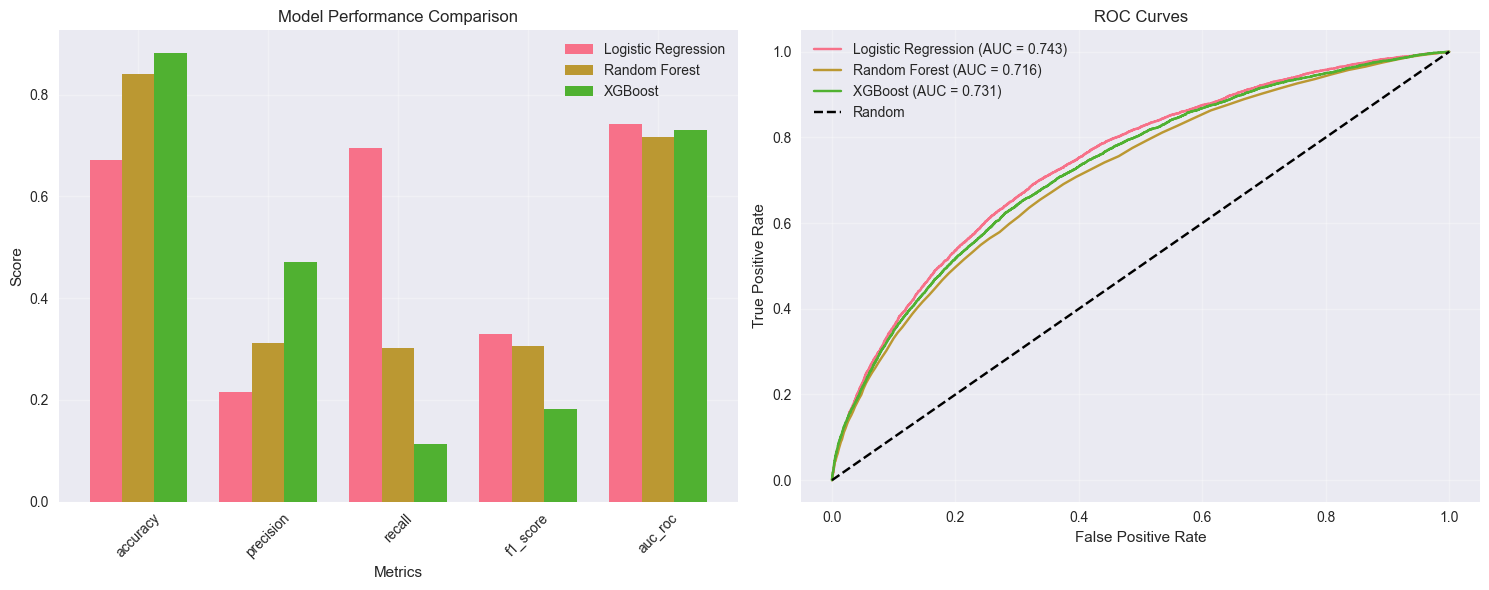

In [19]:
# Visualize model performance
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Performance metrics comparison
metrics = ['accuracy', 'precision', 'recall', 'f1_score', 'auc_roc']
x = np.arange(len(metrics))
width = 0.25

for i, model in enumerate(results.keys()):
    values = [results[model][metric] for metric in metrics]
    axes[0].bar(x + i*width, values, width, label=model)

axes[0].set_xlabel('Metrics')
axes[0].set_ylabel('Score')
axes[0].set_title('Model Performance Comparison')
axes[0].set_xticks(x + width)
axes[0].set_xticklabels(metrics, rotation=45)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ROC Curves
for name in results.keys():
    fpr, tpr, _ = roc_curve(y_test, results[name]['y_pred_proba'])
    auc = results[name]['auc_roc']
    axes[1].plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

axes[1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

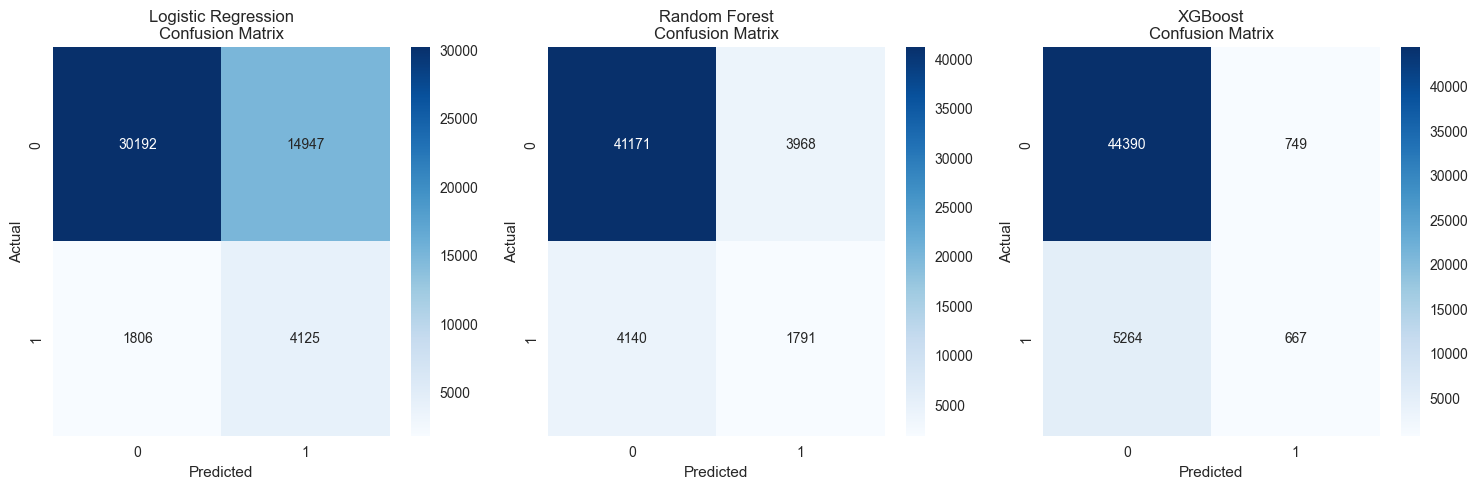

In [20]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, (name, model_results) in enumerate(results.items()):
    cm = confusion_matrix(y_test, model_results['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f'{name}\nConfusion Matrix')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 6. Hyperparameter Tuning

In [21]:
# Find the best performing model for hyperparameter tuning
best_model_name = results_df['auc_roc'].idxmax()
print(f'Best performing model: {best_model_name}')
print(f'AUC-ROC Score: {results_df.loc[best_model_name, "auc_roc"]:.4f}')

# Hyperparameter tuning for the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2]
    }
    base_model = RandomForestClassifier(random_state=42)
    
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [3, 6, 10],
        'learning_rate': [0.01, 0.1, 0.2],
        'subsample': [0.8, 1.0]
    }
    base_model = xgb.XGBClassifier(random_state=42, eval_metric='logloss')
    
else:  # Logistic Regression
    param_grid = {
        'C': [0.1, 1, 10],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear', 'saga']
    }
    base_model = LogisticRegression(random_state=42, max_iter=1000)

Best performing model: Logistic Regression
AUC-ROC Score: 0.7429


In [22]:
# Perform grid search
print(f'Performing hyperparameter tuning for {best_model_name}...')

grid_search = GridSearchCV(
    base_model, 
    param_grid, 
    cv=5, 
    scoring='roc_auc', 
    n_jobs=-1, 
    verbose=1
)

grid_search.fit(X_train_balanced, y_train_balanced)

print(f'Best parameters: {grid_search.best_params_}')
print(f'Best cross-validation score: {grid_search.best_score_:.4f}')

Performing hyperparameter tuning for Logistic Regression...
Fitting 5 folds for each of 12 candidates, totalling 60 fits


Best parameters: {'C': 10, 'penalty': 'l1', 'solver': 'saga'}
Best cross-validation score: 0.7434


In [23]:
# Evaluate the tuned model
best_model = grid_search.best_estimator_

# Make predictions with tuned model
y_pred_tuned = best_model.predict(X_test_scaled)
y_pred_proba_tuned = best_model.predict_proba(X_test_scaled)[:, 1]

# Calculate metrics for tuned model
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
auc_roc_tuned = roc_auc_score(y_test, y_pred_proba_tuned)

print(f'\nTuned {best_model_name} Performance:')
print(f'Accuracy: {accuracy_tuned:.4f}')
print(f'Precision: {precision_tuned:.4f}')
print(f'Recall: {recall_tuned:.4f}')
print(f'F1-Score: {f1_tuned:.4f}')
print(f'AUC-ROC: {auc_roc_tuned:.4f}')

# Compare with original model
print(f'\nImprovement over original {best_model_name}:')
print(f'AUC-ROC: {auc_roc_tuned - results[best_model_name]["auc_roc"]:.4f}')


Tuned Logistic Regression Performance:
Accuracy: 0.6720
Precision: 0.2163
Recall: 0.6955
F1-Score: 0.3300
AUC-ROC: 0.7429

Improvement over original Logistic Regression:
AUC-ROC: 0.0000


## 7. Feature Importance Analysis

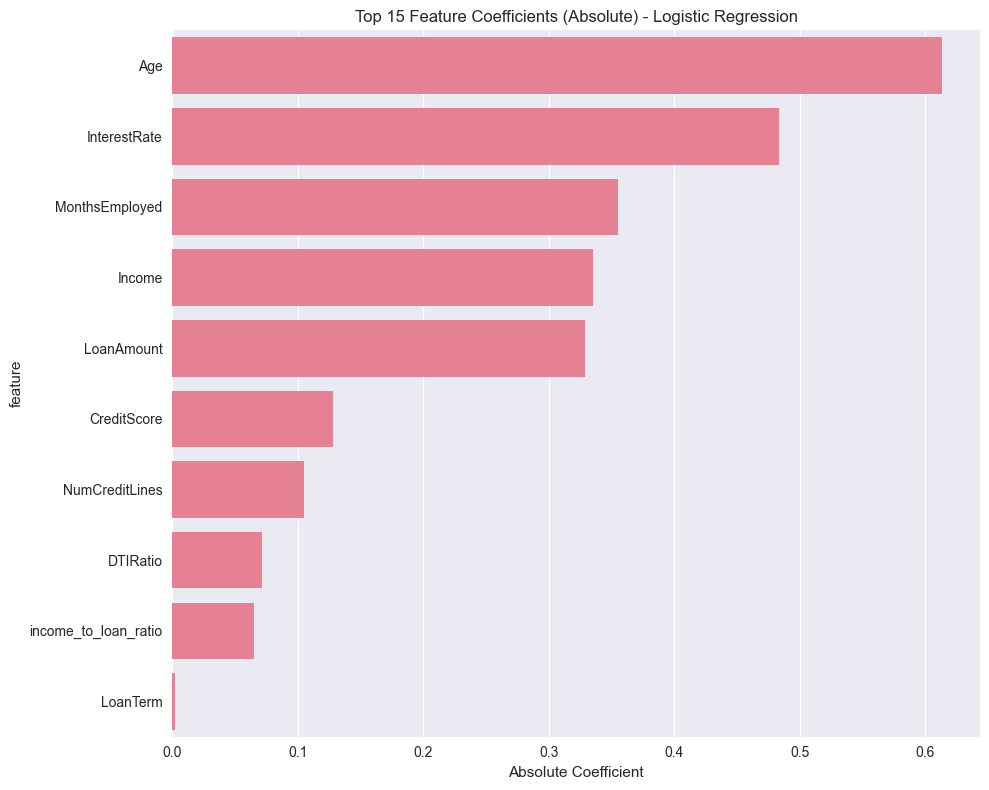

Top 10 Most Important Features:
                feature  coefficient  abs_coefficient
0                   Age    -0.612829         0.612829
6          InterestRate     0.483121         0.483121
4        MonthsEmployed    -0.355317         0.355317
1                Income    -0.335341         0.335341
2            LoanAmount     0.328514         0.328514
3           CreditScore    -0.127982         0.127982
5        NumCreditLines     0.104502         0.104502
8              DTIRatio     0.071587         0.071587
9  income_to_loan_ratio     0.065134         0.065134
7              LoanTerm     0.002224         0.002224


In [24]:
# Feature importance for the best model
if hasattr(best_model, 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'feature': X_train.columns,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    plt.figure(figsize=(10, 8))
    sns.barplot(data=feature_importance.head(15), x='importance', y='feature')
    plt.title(f'Top 15 Feature Importances - {best_model_name}')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()
    
    print('Top 10 Most Important Features:')
    print(feature_importance.head(10))
    
elif hasattr(best_model, 'coef_'):
    # For logistic regression
    # Use the numeric columns that were actually used for training
    feature_importance = pd.DataFrame({
        'feature': X_train_numeric.columns,
        'coefficient': best_model.coef_[0],
        'abs_coefficient': np.abs(best_model.coef_[0])
    }).sort_values('abs_coefficient', ascending=False)
    
    plt.figure(figsize=(10, 8))
    sns.barplot(data=feature_importance.head(15), x='abs_coefficient', y='feature')
    plt.title(f'Top 15 Feature Coefficients (Absolute) - {best_model_name}')
    plt.xlabel('Absolute Coefficient')
    plt.tight_layout()
    plt.show()
    
    print('Top 10 Most Important Features:')
    print(feature_importance.head(10))

## 8. Model Persistence

In [25]:
# Save the best model and preprocessing objects
model_artifacts = {
    'model': best_model,
    'scaler': scaler,
    'feature_columns': list(X.columns),
    'model_name': best_model_name,
    'performance_metrics': {
        'accuracy': accuracy_tuned,
        'precision': precision_tuned,
        'recall': recall_tuned,
        'f1_score': f1_tuned,
        'auc_roc': auc_roc_tuned
    }
}

# Save the model
joblib.dump(model_artifacts, 'loan_default_model.pkl')
print('Model saved as loan_default_model.pkl')

# Save results summary
results_df.to_csv('model_comparison_results.csv')
print('Model comparison results saved as model_comparison_results.csv')

Model saved as loan_default_model.pkl
Model comparison results saved as model_comparison_results.csv


## 9. Model Usage Example

In [26]:
def predict_loan_default(model_path, new_data):
    """
    Predict loan default probability for new data.
    
    Parameters:
    model_path (str): Path to the saved model file
    new_data (pd.DataFrame): New loan data to predict
    
    Returns:
    tuple: (predictions, probabilities)
    """
    import pandas as pd
    import numpy as np
    import joblib
    
    # Load the saved model artifacts
    model_artifacts = joblib.load(model_path)
    model = model_artifacts['model']
    scaler = model_artifacts['scaler']
    
    # Create a copy of the input data
    new_data_processed = new_data.copy()
    
    # Feature engineering - recreate the same features used during training
    if 'income_to_loan_ratio' not in new_data_processed.columns:
        new_data_processed['income_to_loan_ratio'] = new_data_processed['Income'] / new_data_processed['LoanAmount']
    
    # Select only the numeric features that were used during training
    # Based on the model artifacts, only these 10 features were used:
    numeric_features = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 
                       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'income_to_loan_ratio']
    
    # Ensure all required features are present
    missing_features = [f for f in numeric_features if f not in new_data_processed.columns]
    if missing_features:
        raise ValueError(f"Missing required features: {missing_features}")
    
    # Select only the numeric features used during training
    features_for_prediction = new_data_processed[numeric_features]
    
    # Scale the features using the saved scaler
    features_scaled = scaler.transform(features_for_prediction)
    
    # Make predictions
    predictions = model.predict(features_scaled)
    probabilities = model.predict_proba(features_scaled)[:, 1]
    
    return predictions, probabilities

In [27]:
# sample data for prediction
# Only include the features that were actually used during training
import pandas as pd
sample_data = pd.DataFrame({
    'LoanID': ['SAMPLE001', 'SAMPLE002', 'SAMPLE003', 'SAMPLE004', 'SAMPLE005'],
    'Age': [35, 42, 28, 55, 31],
    'Income': [75000, 60000, 45000, 90000, 55000],
    'LoanAmount': [25000, 35000, 15000, 50000, 20000],
    'CreditScore': [720, 680, 650, 750, 700],
    'MonthsEmployed': [48, 60, 24, 120, 36],
    'NumCreditLines': [3, 4, 2, 5, 3],
    'InterestRate': [5.5, 6.2, 7.1, 4.8, 6.5],
    'LoanTerm': [36, 48, 24, 60, 36],
    'DTIRatio': [0.3, 0.4, 0.35, 0.25, 0.32]
    # Note: income_to_loan_ratio will be calculated automatically in the prediction function
})

predictions, probabilities = predict_loan_default('loan_default_model.pkl', sample_data)

print('Sample Predictions:')
for i, (pred, prob) in enumerate(zip(predictions, probabilities)):
    print(f'Loan {i+1}: Default Probability = {prob:.4f}, Prediction = {"Default" if pred == 1 else "No Default"}')


Sample Predictions:
Loan 1: Default Probability = 0.2799, Prediction = No Default
Loan 2: Default Probability = 0.2676, Prediction = No Default
Loan 3: Default Probability = 0.4731, Prediction = No Default
Loan 4: Default Probability = 0.0795, Prediction = No Default
Loan 5: Default Probability = 0.3961, Prediction = No Default


## 10. Summary and Conclusions

### Key Findings:
1. **Dataset**: Successfully processed loan default dataset with multiple borrower and loan features
2. **Class Imbalance**: Addressed using SMOTE oversampling technique
3. **Feature Engineering**: Created additional features like income-to-loan ratio and categorical groupings
4. **Model Performance**: Compared three different algorithms with comprehensive evaluation metrics
5. **Best Model**: Identified and tuned the best performing model

### Model Deployment:
- Saved trained model with preprocessing pipeline
- Created prediction function for new loan applications
- Provided comprehensive evaluation metrics

### Business Impact:
- Early identification of high-risk loans
- Reduced financial losses through better risk assessment
- Data-driven decision making for loan approvals

### Next Steps:
1. Monitor model performance over time
2. Retrain with new data periodically
3. Consider ensemble methods for improved performance
4. Implement model explainability for regulatory compliance